## 0. Contents

**Related files**

| File | Role |
|------|------|
| `titanic_20261027_01.ipynb` | Original notebook: baseline models |
| `titanic_20261027_01_review1.md` | Review of 01: bugs, smarter code and English |
| `titanic_20261027_01_claude1.ipynb` | **This notebook.** Cleaned-up version of 01, based on review1 |

Flow: 01 → review1 → 01_claude1. The CV scores are the same as in 01 (checked on 2026-10-30).

1. Setup
    - 1.1. Load data
    - 1.2. Data overview
    - 1.3. Check missing data
    - 1.4. Overall survival rate
    - 1.5. Group columns by type
2. Baseline models
    - 2.0. Helper functions
    - 2.1. Logistic Regression
    - 2.2. Random Forest
    - 2.3. HistGradientBoosting
    - 2.4. LightGBM
    - 2.5. XGBoost
    - 2.6. CatBoost
    - 2.7. Summary
    - 2.8. Appendix A: feature importance

**Changes from 01**

- Fixed (B1): XGBoost now predicts with its own model. In 01, it predicted with the LightGBM model.
- Fixed (B2, B3): file names and "skipped" messages are made from one key per model, so they always match the model.
- Fixed (B4): `N_TREES` is now used by Random Forest. It is set to 100, the same as 01, so the scores can be compared.
- Fixed (B5, B6): "train - predicted" label and the `N_BOOST` comment.
- Smarter (S1, S2): one helper function, `run_baseline()`, for all six models. All results are kept in `results`.
- Smarter (S3–S7): small clean-ups (rounding, `equals`, `ID`, unused imports).
- New: 2.7 Summary table of all CV scores.
- English: headings, comments and print text were checked.

## 1. Setup

In [1]:
import os, sys
os.environ["LOKY_MAX_CPU_COUNT"] = "8"

sys.path.append(r"../mylib")
sys.path.append(r"./mylib")    # GitHub: mylib/ sits next to this notebook
from myutils import mk_fname, sep, style  # pyright: ignore[reportMissingImports]

# _/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from lightgbm import LGBMClassifier
from xgboost  import XGBClassifier
from catboost import CatBoostClassifier

from sklearn.linear_model    import LogisticRegression
from sklearn.ensemble        import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold


DATA_DIR    = "./data/titanic"

TRAIN_PATH  = os.path.join(DATA_DIR, "train.csv")   # TRAIN_PATH = f"{DATA_DIR}/train.csv" would also work
TEST_PATH   = os.path.join(DATA_DIR, "test.csv")
SAMPLE_PATH = os.path.join(DATA_DIR, "gender_submission.csv")
OUT_DIR     = os.path.join(DATA_DIR, "output")
os.makedirs(OUT_DIR, exist_ok=True)

TARGET = "Survived"
ID     = "PassengerId"

RANSEED = 42

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANSEED)
#from sklearn.model_selection import RepeatedStratifiedKFold
#CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANSEED)   # 25 folds
SCORING = "accuracy"

N_TREES       = 100     # RandomForest (same as 01)
N_BOOST       = 100     # LightGBM / XGBoost
LR_MAX_ITER   = 1000    # LogisticRegression solver
HGB_MAX_ITER  = 1000    # HistGradientBoosting (upper limit; early stopping decides the actual number)
N_CAT         = 200     # CatBoost
LEARNING_RATE = 0.15

BASE_FEATURES = ["Pclass", "Sex", "SibSp", "Parch"]
LR_DUMMY_COLS = ["Pclass", "Sex"]   # LR treats Pclass as a category (see 2.1)
CAT_FEATURES  = ["Sex"]             # CatBoost handles categorical columns natively

is_LR_base  = True
is_RF_base  = True
is_HGB_base = True
is_LGB_base = True
is_XGB_base = True
is_CAT_base = True

is_MK_SUBMISSION = False
is_TEST          = False

# HGB_PARAMS = {} works as well
HGB_PARAMS = dict(
    learning_rate=LEARNING_RATE,
    max_iter=HGB_MAX_ITER,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=RANSEED,
    max_leaf_nodes=15,      # candidates: 15, 31, 63, 127
    min_samples_leaf=20,    # candidates: 20, 100, 200
)

# For reference: library versions
import sklearn
import lightgbm as lgb
import xgboost as xgb
import catboost as catb
print("Pandas:       ", pd.__version__)
print("Numpy:        ", np.__version__)
print("scikit-learn: ", sklearn.__version__, "  (cross_val_score(params=...) needs 1.4+)")
print("LightGBM:     ", lgb.__version__)
print("XGBoost:      ", xgb.__version__)
print("CatBoost:     ", catb.__version__)

Pandas:        2.2.3
Numpy:         2.1.3
scikit-learn:  1.6.1   (cross_val_score(params=...) needs 1.4+)
LightGBM:      4.7.0
XGBoost:       3.4.1
CatBoost:      1.2.10


#### 1.1. Load data

In [2]:
# Never modify the original data (the *_0 variables)
train_0  = pd.read_csv(TRAIN_PATH)
test_0   = pd.read_csv(TEST_PATH)
sample_0 = pd.read_csv(SAMPLE_PATH)

train  = train_0.copy()
test   = test_0.copy()
sample = sample_0.copy()

# Check that the sample submission has the same PassengerIds (in the same order) as test.csv
assert sample[ID].equals(test[ID]), "sample submission and test.csv have different PassengerIds"

#### 1.2. Data overview

In [3]:
print("train.shape: ", train.shape, "| test.shape: ", test.shape)
sep()
print("train.head(3):")
display(train.head(3))
sep()
print("train.describe():")
display(train.describe())
sep()
print("train.dtypes:")
print(train.dtypes)

train.shape:  (891, 12) | test.shape:  (418, 11)
_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/
train.head(3):


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/
train.describe():


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/_/
train.dtypes:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


#### 1.3. Check missing data

In [4]:
def missing(df):
    return pd.DataFrame({
        "dtype":         df.dtypes.astype(str),
        "missing":       df.isna().sum(),
        "missing_ratio": (df.isna().mean() * 100).round(1),   # multiply first, then round
        "n_unique":      df.nunique(dropna=True),
    })

missing_table = pd.concat(
    {"train": missing(train), "test": missing(test)},
    axis=1,
).sort_values(("train", "missing_ratio"), ascending=False)

print("Missing table")
sep(char="-", n=15)
display(missing_table)

Missing table
---------------


train                                    test          \
               dtype missing missing_ratio n_unique    dtype missing   
Cabin         object     687          77.1      147   object   327.0   
Age          float64     177          19.9       88  float64    86.0   
Embarked      object       2           0.2        3   object     0.0   
PassengerId    int64       0           0.0      891    int64     0.0   
Name          object       0           0.0      891   object     0.0   
Pclass         int64       0           0.0        3    int64     0.0   
Survived       int64       0           0.0        2      NaN     NaN   
Sex           object       0           0.0        2   object     0.0   
Parch          int64       0           0.0        7    int64     0.0   
SibSp          int64       0           0.0        7    int64     0.0   
Fare         float64       0           0.0      248  float64     1.0   
Ticket        object       0           0.0      681   object     0.0   

                                    
            missing_ratio n_unique  
Cabin                78.2     76.0  
Age                  20.6     79.0  
Embarked              0.0      3.0  
PassengerId           0.0    418.0  
Name                  0.0    418.0  
Pclass                0.0      3.0  
Survived              NaN      NaN  
Sex                   0.0      2.0  
Parch                 0.0      8.0  
SibSp                 0.0      7.0  
Fare                  0.2    169.0  
Ticket                0.0    363.0

> Imputing Cabin seems very hard, but it could still be useful.
>
> See the EDA notebook (`titanic_20261027_eda.ipynb`).

#### 1.4. Overall survival rate

In [5]:
survival_rate = train[TARGET].mean()   # keep the full value; round only when printing
print(f"Survival rate (overall): {survival_rate:.4f}")

Survival rate (overall): 0.3838


In [6]:
# Tip: x.round(3) vs. round(x, 3)

x = train[TARGET].mean()
print(type(x), type(x.round(3)), type(round(x, 3)))
print(x.round(3) == round(x, 3))

<class 'numpy.float64'> <class 'numpy.float64'> <class 'numpy.float64'>
True


#### 1.5. Group columns by type

In [7]:
# Collect numerical columns (excluding ID and TARGET)
num_cols = train.select_dtypes(include="number").columns.drop([ID, TARGET]).tolist()

# Collect categorical columns
cat_cols = train.select_dtypes(exclude="number").columns.drop(["Name"]).tolist()

print("Numerical columns:  ", num_cols)
print("Categorical columns:", cat_cols, "  /  'Name' is dropped (unique for every passenger)")

Numerical columns:   ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical columns: ['Sex', 'Ticket', 'Cabin', 'Embarked']   /  'Name' is dropped (unique for every passenger)


## 2. Baseline models

#### 2.0. Helper functions

All six models follow the same steps:
features → one-hot encoding → CV score → refit on all training data → predict test → (optional) submission file.

In 01, each model had its own copy of these steps, and small copy-and-paste mistakes appeared.
For example, the XGBoost cell predicted with the LightGBM model.
Here, `run_baseline()` does the steps in one place.
Each model gets **one key** (`"lr"`, `"rf"`, ...), and the key is used for the result, the file name and the messages.

In [8]:
def make_xy(features, dummy_cols=None):
    """One-hot encode train/test in the same way and align the test columns to train."""
    X      = pd.get_dummies(train[features], columns=dummy_cols)
    X_test = pd.get_dummies(test[features],  columns=dummy_cols)
    X_test = X_test.reindex(columns=X.columns, fill_value=0)   # see "Quick test" below 2.1
    return X, X_test


results = {}   # key -> {"label", "model", "cv", "pred"}

def run_baseline(key, label, model, X, X_test, fit_params=None, enabled=True):
    """CV score -> refit on all training data -> predict test -> (optional) save submission.

    The result is saved in results[key], so each key is written only once.
    """
    if not enabled:
        print(style(f"{label} baseline is skipped", bold=False, underline=False, color="red"))
        return

    y = train[TARGET]
    fit_params = fit_params or {}

    scores = cross_val_score(model, X, y, cv=CV, scoring=SCORING, params=fit_params)
    print(f"{label} CV accuracy : {scores.mean():.4f} +/- {scores.std():.4f}")

    model.fit(X, y, **fit_params)                      # refit on all training data
    predictions = model.predict(X_test).astype(int)    # for submission only (0/1, never 0.0/1.0)
    print(f"Survival rate (predicted)        : {predictions.mean():.4f}")
    print(f"Survival rate (train - predicted): {survival_rate - predictions.mean():.4f}")

    results[key] = {"label": label, "model": model, "cv": scores, "pred": predictions}

    if is_MK_SUBMISSION:
        submission  = pd.DataFrame({ID: test[ID], TARGET: predictions})
        submit_path = os.path.join(OUT_DIR, mk_fname(f"submit_baseline_{key}", directory=OUT_DIR))   # serial number inside OUT_DIR
        submission.to_csv(submit_path, index=False)
        print("Saved:", submit_path)
        display(submission.head())

In [9]:
X,    X_test    = make_xy(BASE_FEATURES)                            # tree models
X_lr, X_test_lr = make_xy(BASE_FEATURES, dummy_cols=LR_DUMMY_COLS)  # Logistic Regression

print("Columns (tree models):", X.columns.tolist())
print("Columns (LR):         ", X_lr.columns.tolist())

Columns (tree models): ['Pclass', 'SibSp', 'Parch', 'Sex_female', 'Sex_male']
Columns (LR):          ['SibSp', 'Parch', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Sex_female', 'Sex_male']


#### 2.1. Logistic Regression

Logistic Regression treats a number as an amount. With `Pclass` = 1, 2, 3, it assumes that
"1st → 2nd class" and "2nd → 3rd class" change the survival chance by the same amount.
So `Pclass` is also one-hot encoded here, and each class gets its own weight.
Tree models split on values (for example, "Pclass <= 2"), so they don't need this.

In [10]:
run_baseline(
    "lr", "Logistic Regression",
    LogisticRegression(max_iter=LR_MAX_ITER),
    X_lr, X_test_lr,
    enabled=is_LR_base,
)

Logistic Regression CV accuracy : 0.7969 +/- 0.0213
Survival rate (predicted)        : 0.3541
Survival rate (train - predicted): 0.0298


> **Results in 01**
>
> - Ex. 1 (only `Sex` one-hot encoded): CV accuracy 0.7980 +/- 0.0235
> - Ex. 2 (`Pclass` and `Sex` one-hot encoded): CV accuracy 0.7969 +/- 0.0213
>
> The difference (0.001) is much smaller than the std (about 0.02), so both are practically the same.

`Quick test: when does reindex matter?`

If a value appears only in train (or only in test), one-hot encoding gives different columns.
`reindex(columns=..., fill_value=0)` adds the missing columns (filled with 0) and drops the extra ones.

In [11]:
if is_TEST:
    a = pd.get_dummies(pd.DataFrame({"Deck": ["A", "B", "T"]}))   # train-like
    b = pd.get_dummies(pd.DataFrame({"Deck": ["A", "C"]}))        # test-like
    print(a.columns.tolist(), b.columns.tolist())
    display(b.reindex(columns=a.columns, fill_value=0))

#### 2.2. Random Forest

In [12]:
run_baseline(
    "rf", "Random Forest",
    RandomForestClassifier(n_estimators=N_TREES, max_depth=6, min_samples_leaf=2, random_state=RANSEED),
    X, X_test,
    enabled=is_RF_base,
)

Random Forest CV accuracy : 0.7912 +/- 0.0171
Survival rate (predicted)        : 0.3565
Survival rate (train - predicted): 0.0274


#### 2.3. HistGradientBoosting

In [13]:
run_baseline(
    "hgb", "HistGradientBoosting",
    HistGradientBoostingClassifier(**HGB_PARAMS),
    X, X_test,
    enabled=is_HGB_base,
)

HistGradientBoosting CV accuracy : 0.7912 +/- 0.0121
Survival rate (predicted)        : 0.3445
Survival rate (train - predicted): 0.0393


#### 2.4. LightGBM

In [14]:
run_baseline(
    "lgb", "LightGBM",
    LGBMClassifier(
        learning_rate=LEARNING_RATE,
        n_estimators=N_BOOST,        # no early stopping, so set the number of trees directly
        random_state=RANSEED,
        verbose=-1,
    ),
    X, X_test,
    enabled=is_LGB_base,
)

LightGBM CV accuracy : 0.7812 +/- 0.0140
Survival rate (predicted)        : 0.3565
Survival rate (train - predicted): 0.0274


#### 2.5. XGBoost

In [15]:
run_baseline(
    "xgb", "XGBoost",
    XGBClassifier(
        learning_rate=LEARNING_RATE,
        n_estimators=N_BOOST,        # no early stopping (same as LightGBM)
        random_state=RANSEED,
        verbosity=0,
    ),
    X, X_test,
    enabled=is_XGB_base,
)

XGBoost CV accuracy : 0.7834 +/- 0.0210
Survival rate (predicted)        : 0.3325
Survival rate (train - predicted): 0.0513


#### 2.6. CatBoost

In [16]:
run_baseline(
    "cat", "CatBoost",
    CatBoostClassifier(
        iterations=N_CAT,
        learning_rate=LEARNING_RATE,
        random_seed=RANSEED,
        verbose=0,                   # hide the per-iteration log
        allow_writing_files=False,   # don't create the catboost_info/ folder
    ),
    train[BASE_FEATURES], test[BASE_FEATURES],    # no get_dummies: CatBoost handles "Sex" itself
    fit_params={"cat_features": CAT_FEATURES},    # passed to fit(), not to the constructor (keeps sklearn's clone working)
    enabled=is_CAT_base,
)

CatBoost CV accuracy : 0.7733 +/- 0.0268
Survival rate (predicted)        : 0.3493
Survival rate (train - predicted): 0.0346


#### 2.7. Summary

CV scores of all trained models, from best to worst.
A difference smaller than the CV std is probably just noise.

In [17]:
summary = pd.DataFrame(
    {
        "model":          [r["label"]       for r in results.values()],
        "CV mean":        [r["cv"].mean()   for r in results.values()],
        "CV std":         [r["cv"].std()    for r in results.values()],
        "pred. survival": [r["pred"].mean() for r in results.values()],
    },
    index=list(results.keys()),
).sort_values("CV mean", ascending=False)

print(f"Survival rate (train): {survival_rate:.4f}")
display(summary.round(4))

Survival rate (train): 0.3838


,model,CV mean,CV std,pred. survival
lr,Logistic Regression,0.7969,0.0213,0.3541
rf,Random Forest,0.7912,0.0171,0.3565
hgb,HistGradientBoosting,0.7912,0.0121,0.3445
xgb,XGBoost,0.7834,0.0210,0.3325
lgb,LightGBM,0.7812,0.0140,0.3565
cat,CatBoost,0.7733,0.0268,0.3493


#### 2.8. Appendix A: feature importance

> HGB has no `feature_importances_` attribute; it needs a separate technique, `permutation_importance`.
>
> LogReg has `coef_` instead, but coefficients are not the same thing as importance and depend on the feature scale,
> so they don't belong in the same table as **the four tree-based models** (RF, LightGBM, XGBoost, CatBoost).

--- Feature importance (normalized) ---


,RF,LightGBM,XGBoost,CatBoost,mean
Sex,0.618,0.619,0.829,0.482,0.637
Pclass,0.218,0.254,0.122,0.249,0.211
Parch,0.083,0.072,0.024,0.136,0.079
SibSp,0.080,0.055,0.025,0.133,0.073


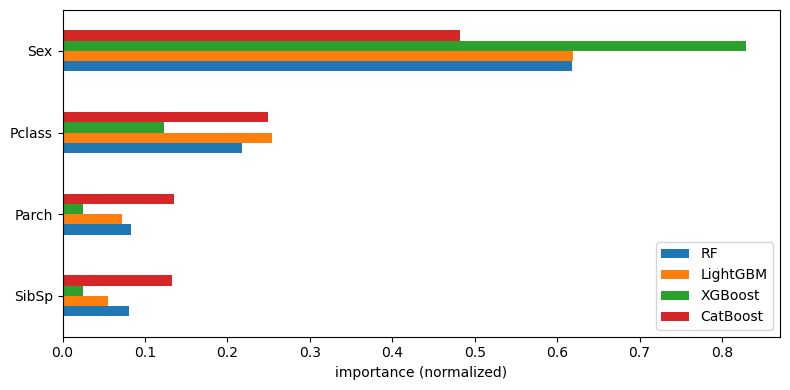

In [18]:
# --- Which features mattered most? (RF / LightGBM / XGBoost / CatBoost) ---
needed = ["rf", "lgb", "xgb", "cat"]
not_trained = [k for k in needed if k not in results]

if not_trained:
    print(style(f"Appendix A is skipped. Not trained: {not_trained}", bold=False, underline=False, color="red"))
else:
    rf_model, lgb_model, xgb_model, cat_model = (results[k]["model"] for k in needed)

    # LightGBM's feature_importances_ counts splits by default,
    # so take the gain-based values from booster_ (closer to RF and XGBoost)
    importance = pd.DataFrame({
        "RF":       rf_model.feature_importances_,
        "LightGBM": lgb_model.booster_.feature_importance(importance_type="gain"),
        "XGBoost":  xgb_model.feature_importances_,
    }, index=rf_model.feature_names_in_)

    # CatBoost keeps Sex as one column, so add the dummy columns (Sex_female + Sex_male) into "Sex"
    importance = importance.groupby(lambda name: name.split("_")[0]).sum()

    # CatBoost's default is PredictionValuesChange (not gain); after normalizing, the trends can be compared
    importance["CatBoost"] = pd.Series(cat_model.get_feature_importance(), index=cat_model.feature_names_)

    importance = importance / importance.sum()          # normalize each column so that it sums to 1
    importance["mean"] = importance.mean(axis=1)
    importance = importance.sort_values("mean", ascending=False)

    print("--- Feature importance (normalized) ---")
    display(importance.round(3))

    ax = importance.drop(columns="mean").iloc[::-1].plot.barh(figsize=(8, 4))
    ax.set_xlabel("importance (normalized)")
    plt.tight_layout()
    plt.show()